In [23]:
import kagglehub
path = kagglehub.dataset_download("moltean/fruits")
print(path)

Using Colab cache for faster access to the 'fruits' dataset.
/kaggle/input/fruits


In [24]:
import os, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


DATA_DIR = None
for r, dirs, _ in os.walk(path):
    if "Training" in dirs:
        DATA_DIR = os.path.join(r, "Training")
        break

CLASSES = ["Apple Red 1", "Banana 1", "Orange 1", "Kiwi 1", "Strawberry 1"]
paths = {}
for c in CLASSES:
    class_dir = os.path.join(DATA_DIR, c)
    paths[c] = []
    for f in os.listdir(class_dir):
        if f.lower().endswith((".jpg", ".png")):
            paths[c].append(os.path.join(class_dir, f))
counts = {}
for c in CLASSES:
    counts[c] = len(paths[c])
print(counts)

{'Apple Red 1': 492, 'Banana 1': 490, 'Orange 1': 479, 'Kiwi 1': 466, 'Strawberry 1': 492}


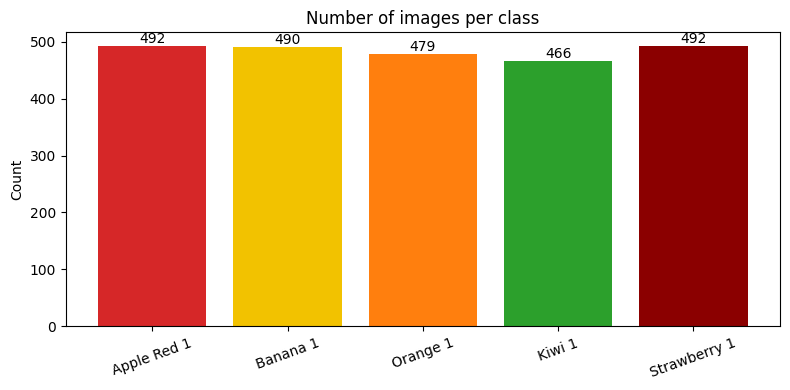

In [25]:
counts = {c: len(p) for c, p in paths.items()}

plt.figure(figsize=(8, 4))
bars = plt.bar(counts.keys(), counts.values(),
               color=["#d62728", "#f2c200", "#ff7f0e", "#2ca02c", "#8b0000"])
plt.bar_label(bars)
plt.title("Number of images per class")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

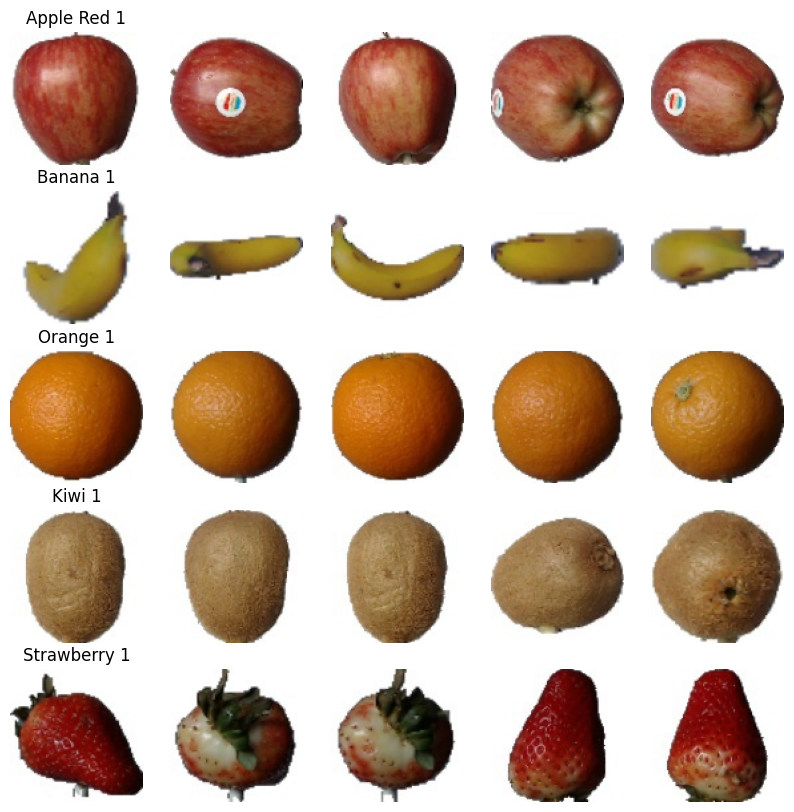

Image sizes found: {(100, 100)}


In [26]:
N = 5
fig, axes = plt.subplots(len(CLASSES), N, figsize=(2 * N, 2 * len(CLASSES)))
for i, c in enumerate(CLASSES):
    for j, p in enumerate(random.sample(paths[c], N)):
        axes[i, j].imshow(Image.open(p).convert("RGB"))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(c)

plt.show()

sizes = set()
for c in CLASSES:
    for p in paths[c]:
        sizes.add(Image.open(p).size)

print("Image sizes found:", sizes)

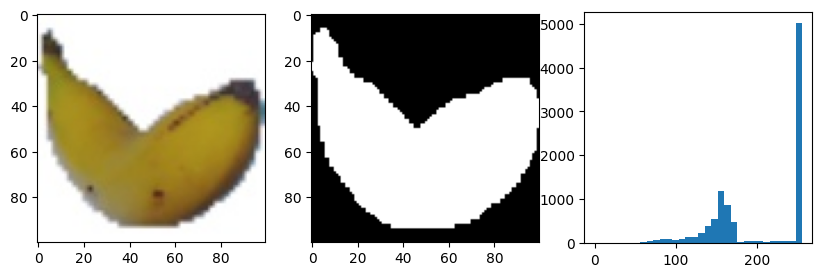

In [27]:
p = random.choice(paths["Banana 1"])
img = np.array(Image.open(p).convert("RGB"))
mask = ~(img > 240).all(axis=2)

fig, ax = plt.subplots(1, 3, figsize=(10, 3))
ax[0].imshow(img)
ax[1].imshow(mask, cmap="gray")
ax[2].hist(img[..., 0].ravel(), bins=32, range=(0, 256))
plt.show()

In [28]:
BINS = 32

def img_hist(img, bins=BINS):
    mask = ~(img > 240).all(axis=2)
    feats = []
    for ch in range(3):
        h, _ = np.histogram(img[..., ch][mask], bins=bins, range=(0, 256))
        feats.append(h / max(h.sum(), 1))
    return np.concatenate(feats)

def mean_hist(file_list, bins=BINS, n=150, seed=13):
    random.seed(seed)
    sample = random.sample(file_list, min(n, len(file_list)))

    all_hists = []
    for p in sample:
        img = np.array(Image.open(p).convert("RGB"))
        all_hists.append(img_hist(img, bins))

    H = np.mean(all_hists, axis=0)
    return H.reshape(3, bins)

hists = {}
for c in CLASSES:
    hists[c] = mean_hist(paths[c])
print("Done. Vector length per image:", BINS * 3)

Done. Vector length per image: 96


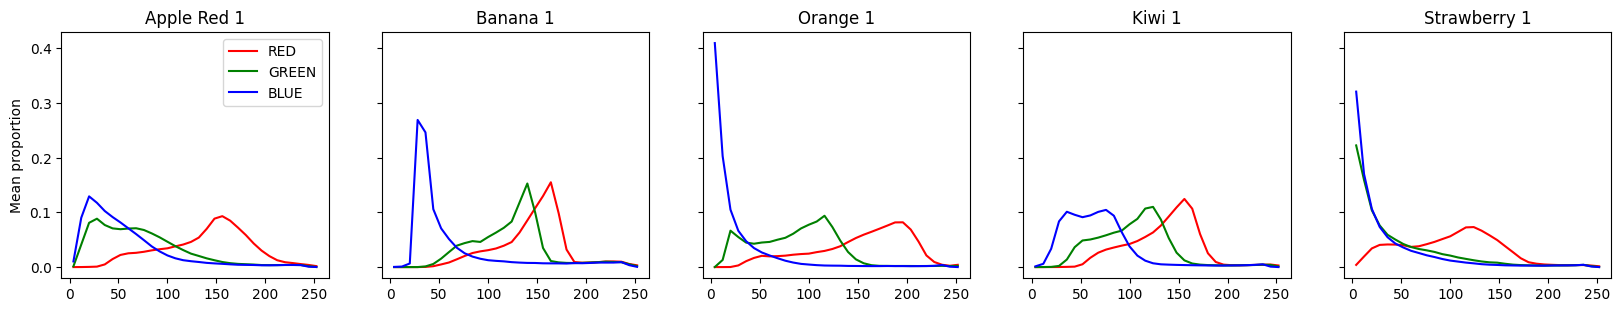

In [29]:
centers = (np.arange(BINS) + 0.5) * (256 / BINS)
fig, axes = plt.subplots(1, len(CLASSES), figsize=(4 * len(CLASSES), 3.2), sharey=True)
for ax, c in zip(axes, CLASSES):
    for ch, col in enumerate(["red", "green", "blue"]):
        ax.plot(centers, hists[c][ch], color=col, label=col.upper())
    ax.set_title(c)
axes[0].set_ylabel("Mean proportion")
axes[0].legend()
plt.show()

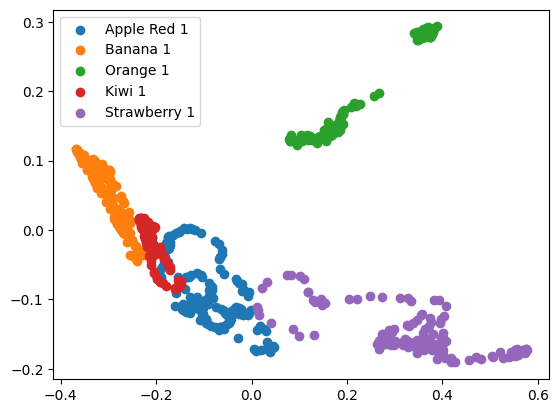

X shape: (750, 96)


In [30]:
from sklearn.decomposition import PCA

X, y = [], []
for ci, c in enumerate(CLASSES):
    for p in random.sample(paths[c], min(150, len(paths[c]))):
        X.append(img_hist(np.array(Image.open(p).convert("RGB"))))
        y.append(ci)
X, y = np.array(X), np.array(y)

Z = PCA(n_components=2).fit_transform(X)

for ci, c in enumerate(CLASSES):
    plt.scatter(Z[y == ci, 0], Z[y == ci, 1], label=c)
plt.legend()
plt.show()
print("X shape:", X.shape)

In [31]:
X, y = [], []
for ci, c in enumerate(CLASSES):
    for p in paths[c]:
        img = Image.open(p).convert("RGB").resize((100, 100))
        X.append(img_hist(np.array(img)))
        y.append(ci)

X = np.array(X)
y = np.array(y)
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2419, 96)
y shape: (2419,)


In [32]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.20
VAL_SIZE = 0.20


X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=VAL_SIZE / (1 - TEST_SIZE), stratify=y_temp, random_state=42
)

print("Train:", X_train.shape)
print("Val:  ", X_val.shape)
print("Test: ", X_test.shape)


for name, labels in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(name, np.bincount(labels))

Train: (1451, 96)
Val:   (484, 96)
Test:  (484, 96)
Train [295 294 287 280 295]
Val [98 98 96 93 99]
Test [99 98 96 93 98]


In [33]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [34]:
os.makedirs("data", exist_ok=True)
np.savez("data/split_scaled.npz",
         X_train_scaled=X_train_scaled, X_val_scaled=X_val_scaled, X_test_scaled=X_test_scaled,
         y_train=y_train, y_val=y_val, y_test=y_test)


In [35]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, accuracy_score,
                             confusion_matrix, classification_report)

X_tr_data = X_train_scaled
X_va_data = X_val_scaled
X_te_data = X_test_scaled

N_CLASSES = len(CLASSES)

def cluster_to_label_map(clusters, true_labels):
    """Map each cluster id to the most frequent true label inside it."""
    mapping = {}
    for k in range(N_CLASSES):
        members = true_labels[clusters == k]
        if len(members) > 0:
            mapping[k] = np.bincount(members, minlength=N_CLASSES).argmax()
        else:
            mapping[k] = -1
    return mapping

def apply_map(clusters, mapping):
    return np.array([mapping[k] for k in clusters])

def build_features(n_comp):
    """Features are already scaled. Optionally apply PCA fitted on train only."""
    if n_comp is None:
        return X_tr_data, X_va_data, X_te_data
    pca = PCA(n_components=n_comp, random_state=42).fit(X_tr_data)
    return pca.transform(X_tr_data), pca.transform(X_va_data), pca.transform(X_te_data)

In [36]:
results = []
for n_comp in [None, 10, 20, 30, 50]:
    tr, va, te = build_features(n_comp)
    km = KMeans(n_clusters=N_CLASSES, n_init=10, random_state=42).fit(tr)

    mapping = cluster_to_label_map(km.labels_, y_train)
    val_clusters = km.predict(va)
    val_pred = apply_map(val_clusters, mapping)

    val_acc = accuracy_score(y_val, val_pred)
    val_sil = silhouette_score(va, val_clusters)
    results.append((n_comp, val_acc, val_sil))
    print(f"PCA components: {n_comp} | val accuracy: {val_acc:.4f} | val silhouette: {val_sil:.4f}")

best_n_comp = max(results, key=lambda r: r[1])[0]
print("\nBest number of PCA components:", best_n_comp)

PCA components: None | val accuracy: 0.9525 | val silhouette: 0.3382
PCA components: 10 | val accuracy: 0.9525 | val silhouette: 0.4567
PCA components: 20 | val accuracy: 0.9545 | val silhouette: 0.3953
PCA components: 30 | val accuracy: 0.9525 | val silhouette: 0.3738
PCA components: 50 | val accuracy: 0.9525 | val silhouette: 0.3513

Best number of PCA components: 20


In [37]:
tr, va, te = build_features(best_n_comp)
km = KMeans(n_clusters=N_CLASSES, n_init=10, random_state=42).fit(tr)

mapping = cluster_to_label_map(km.labels_, y_train)
print("Cluster -> class mapping:", {k: CLASSES[v] for k, v in mapping.items()})

test_clusters = km.predict(te)
test_pred = apply_map(test_clusters, mapping)

print(f"\nTest accuracy: {accuracy_score(y_test, test_pred):.4f}")
print(f"Test silhouette: {silhouette_score(te, test_clusters):.4f}")
print("\nClassification report:")
print(classification_report(y_test, test_pred, target_names=CLASSES))

Cluster -> class mapping: {0: 'Banana 1', 1: 'Strawberry 1', 2: 'Kiwi 1', 3: 'Orange 1', 4: 'Apple Red 1'}

Test accuracy: 0.9401
Test silhouette: 0.3825

Classification report:
              precision    recall  f1-score   support

 Apple Red 1       0.80      0.94      0.87        99
    Banana 1       1.00      1.00      1.00        98
    Orange 1       1.00      1.00      1.00        96
      Kiwi 1       0.94      0.94      0.94        93
Strawberry 1       1.00      0.83      0.91        98

    accuracy                           0.94       484
   macro avg       0.95      0.94      0.94       484
weighted avg       0.95      0.94      0.94       484



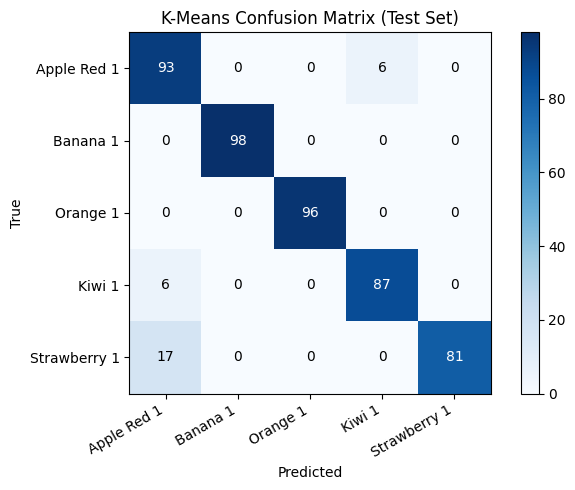

In [38]:
cm = confusion_matrix(y_test, test_pred)

plt.figure(figsize=(7, 5))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(N_CLASSES), CLASSES, rotation=30, ha="right")
plt.yticks(range(N_CLASSES), CLASSES)

for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("K-Means Confusion Matrix (Test Set)")
plt.tight_layout()
plt.show()

In [39]:
from sklearn.linear_model import LogisticRegression

lr_val_acc = {}
for C in [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]:
    model = LogisticRegression(C=C, max_iter=3000, random_state=42).fit(X_train_scaled, y_train)
    lr_val_acc[C] = accuracy_score(y_val, model.predict(X_val_scaled))
    print(f"LogReg C={C:<8} | val accuracy: {lr_val_acc[C]:.4f}")

best_C = max(sorted(lr_val_acc), key=lambda c: (lr_val_acc[c], -c))
print("\nBest C:", best_C)

LogReg C=0.0001   | val accuracy: 0.9814
LogReg C=0.001    | val accuracy: 0.9979
LogReg C=0.01     | val accuracy: 1.0000
LogReg C=0.1      | val accuracy: 1.0000
LogReg C=1        | val accuracy: 1.0000
LogReg C=10       | val accuracy: 1.0000
LogReg C=100      | val accuracy: 1.0000

Best C: 0.01


In [40]:
lr_model = LogisticRegression(C=best_C, max_iter=3000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

lr_test_pred = lr_model.predict(X_test_scaled)

print(f"Logistic Regression Test Accuracy: {accuracy_score(y_test, lr_test_pred):.4f}")
print("\nClassification report:")
print(classification_report(y_test, lr_test_pred, target_names=CLASSES))

Logistic Regression Test Accuracy: 1.0000

Classification report:
              precision    recall  f1-score   support

 Apple Red 1       1.00      1.00      1.00        99
    Banana 1       1.00      1.00      1.00        98
    Orange 1       1.00      1.00      1.00        96
      Kiwi 1       1.00      1.00      1.00        93
Strawberry 1       1.00      1.00      1.00        98

    accuracy                           1.00       484
   macro avg       1.00      1.00      1.00       484
weighted avg       1.00      1.00      1.00       484



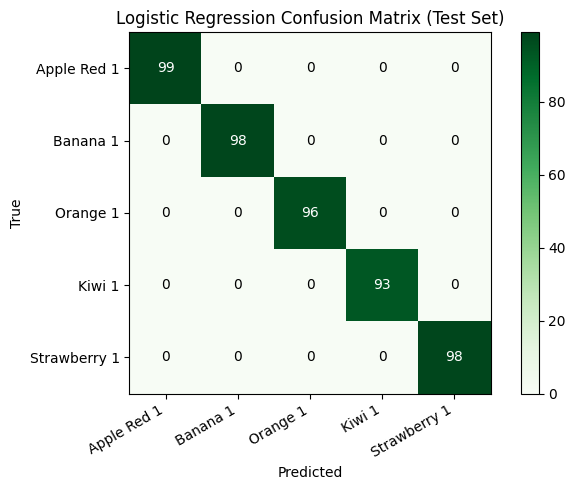

In [41]:
cm_lr = confusion_matrix(y_test, lr_test_pred)

plt.figure(figsize=(7, 5))
plt.imshow(cm_lr, cmap="Greens")
plt.colorbar()
plt.xticks(range(N_CLASSES), CLASSES, rotation=30, ha="right")
plt.yticks(range(N_CLASSES), CLASSES)

for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        plt.text(j, i, cm_lr[i, j], ha="center", va="center",
                 color="white" if cm_lr[i, j] > cm_lr.max() / 2 else "black")

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Logistic Regression Confusion Matrix (Test Set)")
plt.tight_layout()
plt.show()

In [42]:
from sklearn.neighbors import KNeighborsClassifier

knn_val_acc = {}
for weights in ["uniform", "distance"]:
    for k in [1, 3, 5, 7, 9, 11, 15, 21]:
        model = KNeighborsClassifier(n_neighbors=k, weights=weights).fit(X_train_scaled, y_train)
        knn_val_acc[(k, weights)] = accuracy_score(y_val, model.predict(X_val_scaled))
        print(f"KNN k={k:<3} | weights={weights:<8} | val accuracy: {knn_val_acc[(k, weights)]:.4f}")


best_k, best_w = max(knn_val_acc, key=lambda kw: (knn_val_acc[kw], kw[0], kw[1] == "uniform"))
print(f"\nBest KNN -> k: {best_k}, weights: {best_w}")

KNN k=1   | weights=uniform  | val accuracy: 1.0000
KNN k=3   | weights=uniform  | val accuracy: 1.0000
KNN k=5   | weights=uniform  | val accuracy: 1.0000
KNN k=7   | weights=uniform  | val accuracy: 1.0000
KNN k=9   | weights=uniform  | val accuracy: 1.0000
KNN k=11  | weights=uniform  | val accuracy: 1.0000
KNN k=15  | weights=uniform  | val accuracy: 1.0000
KNN k=21  | weights=uniform  | val accuracy: 1.0000
KNN k=1   | weights=distance | val accuracy: 1.0000
KNN k=3   | weights=distance | val accuracy: 1.0000
KNN k=5   | weights=distance | val accuracy: 1.0000
KNN k=7   | weights=distance | val accuracy: 1.0000
KNN k=9   | weights=distance | val accuracy: 1.0000
KNN k=11  | weights=distance | val accuracy: 1.0000
KNN k=15  | weights=distance | val accuracy: 1.0000
KNN k=21  | weights=distance | val accuracy: 1.0000

Best KNN -> k: 21, weights: uniform


In [43]:
knn_model = KNeighborsClassifier(n_neighbors=best_k, weights=best_w)
knn_model.fit(X_train_scaled, y_train)

knn_test_pred = knn_model.predict(X_test_scaled)

print(f"KNN Test Accuracy: {accuracy_score(y_test, knn_test_pred):.4f}")
print("\nClassification report:")
print(classification_report(y_test, knn_test_pred, target_names=CLASSES))

KNN Test Accuracy: 1.0000

Classification report:
              precision    recall  f1-score   support

 Apple Red 1       1.00      1.00      1.00        99
    Banana 1       1.00      1.00      1.00        98
    Orange 1       1.00      1.00      1.00        96
      Kiwi 1       1.00      1.00      1.00        93
Strawberry 1       1.00      1.00      1.00        98

    accuracy                           1.00       484
   macro avg       1.00      1.00      1.00       484
weighted avg       1.00      1.00      1.00       484



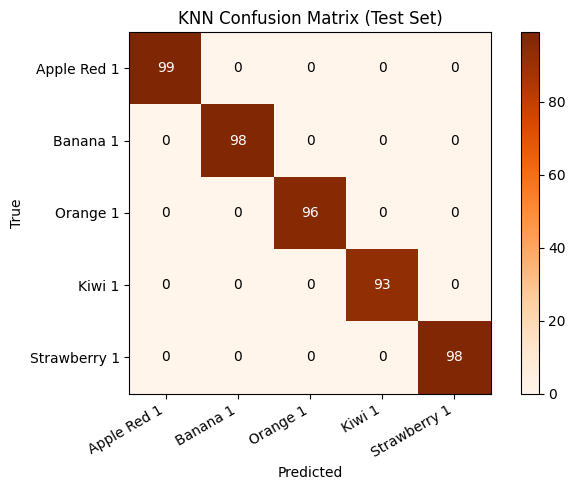

In [44]:
cm_knn = confusion_matrix(y_test, knn_test_pred)

plt.figure(figsize=(7, 5))
plt.imshow(cm_knn, cmap="Oranges")
plt.colorbar()
plt.xticks(range(N_CLASSES), CLASSES, rotation=30, ha="right")
plt.yticks(range(N_CLASSES), CLASSES)

for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        plt.text(j, i, cm_knn[i, j], ha="center", va="center",
                 color="white" if cm_knn[i, j] > cm_knn.max() / 2 else "black")

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("KNN Confusion Matrix (Test Set)")
plt.tight_layout()
plt.show()

In [53]:
import joblib
from sklearn.pipeline import Pipeline

SAVE_DIR = "models"
os.makedirs(SAVE_DIR, exist_ok=True)

# remove the old standalone scaler file if it exists
old_scaler = os.path.join(SAVE_DIR, "scaler.joblib")
if os.path.exists(old_scaler):
    os.remove(old_scaler)

# Logistic Regression: scaler + model
lr_pipe = Pipeline([("scaler", scaler), ("model", lr_model)])

# KNN: scaler + model
knn_pipe = Pipeline([("scaler", scaler), ("model", knn_model)])

# K-Means: scaler + (optional PCA) + kmeans
km_steps = [("scaler", scaler)]
if best_n_comp is not None:
    km_steps.append(("pca", PCA(n_components=best_n_comp, random_state=42).fit(X_train_scaled)))
km_steps.append(("kmeans", km))
km_pipe = Pipeline(km_steps)

joblib.dump(lr_pipe, f"{SAVE_DIR}/logistic_regression.joblib")
joblib.dump(knn_pipe, f"{SAVE_DIR}/knn.joblib")
joblib.dump(
    {"pipeline": km_pipe, "cluster_to_label": mapping, "classes": CLASSES},
    f"{SAVE_DIR}/kmeans.joblib",
)

print("Saved:", sorted(os.listdir(SAVE_DIR)))

Saved: ['kmeans.joblib', 'knn.joblib', 'logistic_regression.joblib']


In [54]:
lr_loaded = joblib.load(f"{SAVE_DIR}/logistic_regression.joblib")
knn_loaded = joblib.load(f"{SAVE_DIR}/knn.joblib")
km_bundle = joblib.load(f"{SAVE_DIR}/kmeans.joblib")

print("LR same predictions:", (lr_loaded.predict(X_test) == lr_test_pred).all())
print("KNN same predictions:", (knn_loaded.predict(X_test) == knn_test_pred).all())

km_pred = apply_map(km_bundle["pipeline"].predict(X_test), km_bundle["cluster_to_label"])
print("K-Means same predictions:", (km_pred == test_pred).all())

LR same predictions: True
KNN same predictions: True
K-Means same predictions: True


In [55]:
import shutil
from google.colab import files

shutil.make_archive("models_images", "zip", SAVE_DIR)
files.download("models_images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>